In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("Student_Performance.csv")
np.random.seed(42)

cols = ["age", "study_hours", "attendance_percentage", "internet_access", "gender"]
for col in cols:
    idx = df.sample(frac=0.20).index
    df.loc[idx, col] = np.nan

df = pd.concat([df, df.sample(100)], ignore_index=True)

# Add redundant columns
df["age_copy"] = df["age"]
df["gender_copy"] = df["gender"]

df.to_csv("Student_Performance_dirty.csv", index=False)
print(df.shape)

(25100, 18)


In [2]:
#Display the first  any number of you choose of rows.
df=pd.read_csv("Student_Performance_dirty.csv")
print(df.head(10))


   student_id   age  gender school_type parent_education  study_hours  \
0           1  14.0    male      public    post graduate          3.1   
1           2  18.0  female      public         graduate          3.7   
2           3  17.0     NaN     private    post graduate          7.9   
3           4  16.0   other      public      high school          1.1   
4           5  16.0  female      public      high school          NaN   
5           6  19.0    male      public        no formal          3.8   
6           7  14.0  female     private    post graduate          1.8   
7           8  18.0  female     private    post graduate          5.6   
8           9  15.0     NaN     private      high school          3.2   
9          10  14.0  female      public          diploma          6.8   

   attendance_percentage internet_access travel_time extra_activities  \
0                   84.3             yes     <15 min              yes   
1                   87.8             yes     >60 m

In [3]:
#Display the last any number of you choose of rows.
df=pd.read_csv("Student_Performance_dirty.csv")

print(df.tail(10))

       student_id   age  gender school_type parent_education  study_hours  \
25090        7698  15.0  female     private      high school          7.7   
25091        1715  17.0   other      public              phd          1.7   
25092        3548   NaN  female      public          diploma          4.3   
25093        4959  19.0   other     private      high school          1.3   
25094       11958   NaN   other      public    post graduate          1.3   
25095        7875  15.0  female      public         graduate          8.0   
25096       10054  16.0   other      public         graduate          6.5   
25097       12665  15.0   other     private        no formal          6.7   
25098        8110  18.0   other      public      high school          2.9   
25099       10980  18.0    male     private    post graduate          7.9   

       attendance_percentage internet_access travel_time extra_activities  \
25090                   62.3             NaN   15-30 min               no  

In [4]:
#Display the number of rows and columns.
df=pd.read_csv("Student_Performance_dirty.csv")

print("Rows : ",df.shape[0])
print("Columns : ",df.shape[1])

Rows :  25100
Columns :  18


In [5]:
#Identify the data type of each column.

df=pd.read_csv("Student_Performance_dirty.csv")

print(df.dtypes)

student_id                 int64
age                      float64
gender                       str
school_type                  str
parent_education             str
study_hours              float64
attendance_percentage    float64
internet_access              str
travel_time                  str
extra_activities             str
study_method                 str
math_score               float64
science_score            float64
english_score            float64
overall_score            float64
final_grade                  str
age_copy                 float64
gender_copy                  str
dtype: object


In [6]:
#Generate descriptive statistics
df.describe(include="all")

,student_id,age,gender,school_type,parent_education,study_hours,attendance_percentage,internet_access,travel_time,extra_activities,study_method,math_score,science_score,english_score,overall_score,final_grade,age_copy,gender_copy
count,25100.000000,20084.000000,20084,25100,25100,20088.000000,20079.000000,20080,25100,25100,25100,25100.000000,25100.000000,25100.000000,25100.000000,25100,20084.000000,20084
unique,NaN,NaN,3,2,6,NaN,NaN,2,4,2,6,NaN,NaN,NaN,NaN,6,NaN,3
top,NaN,NaN,other,private,diploma,NaN,NaN,yes,15-30 min,no,mixed,NaN,NaN,NaN,NaN,d,NaN,other
freq,NaN,NaN,6770,12772,4325,NaN,NaN,17031,6386,12555,4357,NaN,NaN,NaN,NaN,6335,NaN,6770
mean,7492.968526,16.486507,NaN,NaN,NaN,4.245993,75.065342,NaN,NaN,NaN,NaN,63.788896,63.754745,63.690458,64.012434,NaN,16.486507,NaN
std,4322.114456,1.702656,NaN,NaN,NaN,2.168705,14.395909,NaN,NaN,NaN,NaN,20.866214,20.963968,20.790727,18.926996,NaN,1.702656,NaN
min,1.000000,14.000000,NaN,NaN,NaN,0.500000,50.000000,NaN,NaN,NaN,NaN,0.000000,0.000000,0.000000,14.500000,NaN,14.000000,NaN
25%,3745.750000,15.000000,NaN,NaN,NaN,2.400000,62.700000,NaN,NaN,NaN,NaN,48.300000,48.200000,48.400000,49.000000,NaN,15.000000,NaN
50%,7461.500000,16.000000,NaN,NaN,NaN,4.300000,75.000000,NaN,NaN,NaN,NaN,64.100000,64.100000,64.200000,64.200000,NaN,16.000000,NaN
75%,11249.000000,18.000000,NaN,NaN,NaN,6.100000,87.500000,NaN,NaN,NaN,NaN,80.000000,80.000000,80.000000,79.000000,NaN,18.000000,NaN


In [7]:
#Check for missing values in each column.
print(df.isnull().sum())

student_id                  0
age                      5016
gender                   5016
school_type                 0
parent_education            0
study_hours              5012
attendance_percentage    5021
internet_access          5020
travel_time                 0
extra_activities            0
study_method                0
math_score                  0
science_score               0
english_score               0
overall_score               0
final_grade                 0
age_copy                 5016
gender_copy              5016
dtype: int64


In [8]:
#Check for only missing values in each column.
nulls=df.isnull().mean().mul(100).round(2);
print(nulls[nulls>0])

age                      19.98
gender                   19.98
study_hours              19.97
attendance_percentage    20.00
internet_access          20.00
age_copy                 19.98
gender_copy              19.98
dtype: float64


In [9]:
#Check for duplicated rows.
print(df.duplicated().sum())

2011


In [10]:

# Check for duplicated rows.

print(df[df.duplicated()])

       student_id   age  gender school_type parent_education  study_hours  \
15001         861  19.0   other      public    post graduate          0.8   
15003       13419  16.0   other     private         graduate          0.7   
15019         770  16.0    male      public        no formal          NaN   
15020       10584  16.0    male     private          diploma          NaN   
15025        5052  14.0    male      public         graduate          1.1   
...           ...   ...     ...         ...              ...          ...   
25095        7875  15.0  female      public         graduate          8.0   
25096       10054  16.0   other      public         graduate          6.5   
25097       12665  15.0   other     private        no formal          6.7   
25098        8110  18.0   other      public      high school          2.9   
25099       10980  18.0    male     private    post graduate          7.9   

       attendance_percentage internet_access travel_time extra_activities  

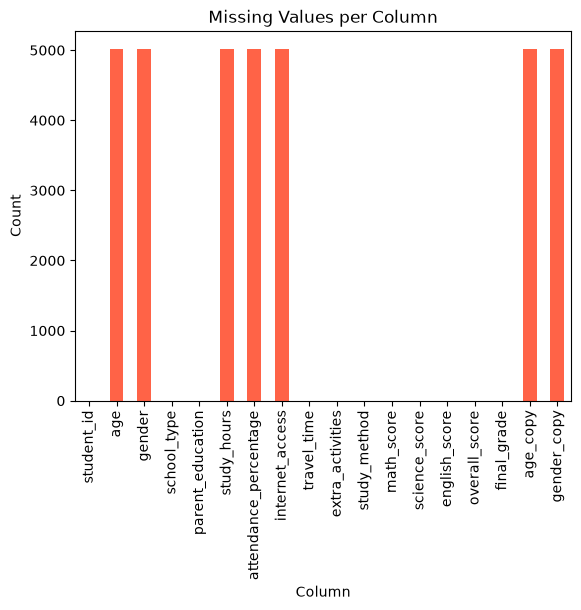

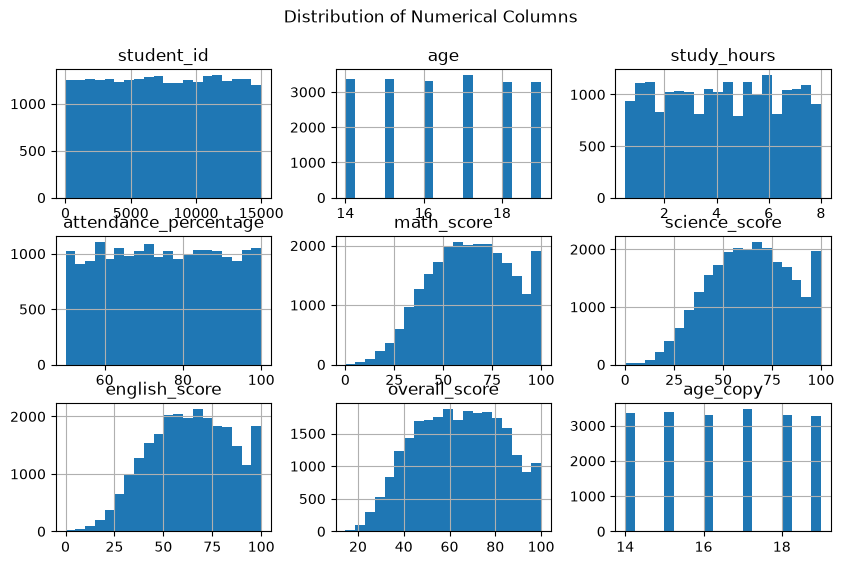

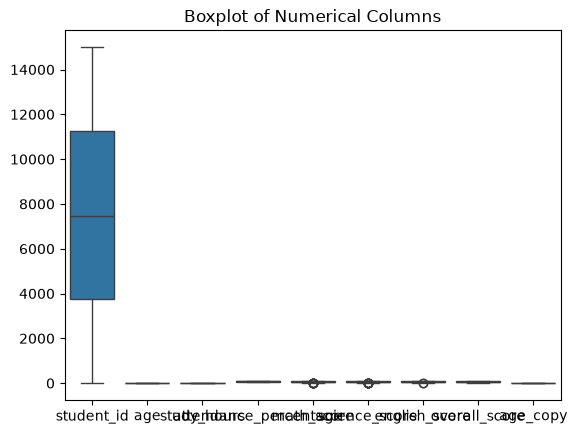

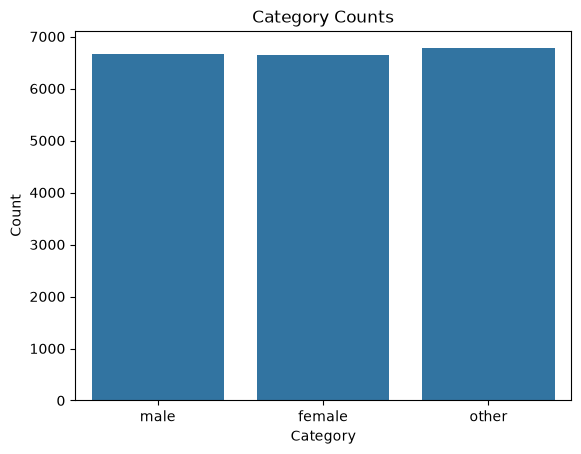

In [11]:
# Use visuals that help you in exploration.

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df.isna().sum().plot(kind="bar", color="tomato")
plt.title("Missing Values per Column")
plt.xlabel("Column"); plt.ylabel("Count")
plt.show()

# 2) توزيع الأعمدة الرقمية
df.select_dtypes("number").hist(figsize=(10, 6), bins=20)
plt.suptitle("Distribution of Numerical Columns")
plt.show()


# 3) الـ outliers
sns.boxplot(data=df.select_dtypes("number"))
plt.title("Boxplot of Numerical Columns")
plt.show()


# 4) الـ categories
sns.countplot(data=df, x="gender")
plt.title("Category Counts")
plt.xlabel("Category"); plt.ylabel("Count")
plt.show()

In [12]:

#Drop the redundant columns and null records you have (depend on your point of view).

print("Shape BEFORE:", df.shape)

# 1) نشوف الأعمدة المشكلة
print("\nConstant columns:", [c for c in df.columns if df[c].nunique() <= 1])
print("ID-like columns:", [c for c in df.columns if df[c].nunique() == len(df)])
print("\nNull % per column:")
print((df.isna().mean() * 100).round(1).sort_values(ascending=False))

Shape BEFORE: (25100, 18)

Constant columns: []
ID-like columns: []

Null % per column:
gender_copy              20.0
gender                   20.0
age_copy                 20.0
study_hours              20.0
attendance_percentage    20.0
internet_access          20.0
age                      20.0
science_score             0.0
final_grade               0.0
overall_score             0.0
english_score             0.0
student_id                0.0
math_score                0.0
study_method              0.0
travel_time               0.0
parent_education          0.0
school_type               0.0
extra_activities          0.0
dtype: float64


In [13]:
#Drop the redundant columns and null records you have (depend on your point of view).

print("Shape BEFORE:", df.shape)
df = df.drop(columns=["student_id"])
df = df.drop(columns=["age_copy"])
df = df.drop(columns=["gender_copy"])
df = df.dropna(subset=["age"])

print("Shape AFTER:", df.shape)

print("\nDuplicated rows:", df.duplicated().sum())

Shape BEFORE: (25100, 18)
Shape AFTER: (20084, 15)

Duplicated rows: 1932


In [14]:
# Handle missing values by filling the nulls for all nullable columns you have.
# 2) الأعمدة الرقمية -> median
num_cols = df.select_dtypes(include="number").columns
for col in num_cols:
    if df[col].isna().any():
        df[col] = df[col].fillna(df[col].median())

# 3) الأعمدة النصية -> mode
cat_cols = df.select_dtypes(include=["object", "category"]).columns
for col in cat_cols:
    if df[col].isna().any():
        df[col] = df[col].fillna(df[col].mode()[0])

# 4) بعد الملء: نتأكد
print("\nMissing values AFTER:")
print(df.isna().sum())

C:\Users\Master\AppData\Local\Temp\ipykernel_12316\3720553553.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=["object", "category"]).columns



Missing values AFTER:
age                      0
gender                   0
school_type              0
parent_education         0
study_hours              0
attendance_percentage    0
internet_access          0
travel_time              0
extra_activities         0
study_method             0
math_score               0
science_score            0
english_score            0
overall_score            0
final_grade              0
dtype: int64


In [15]:
#Identify and remove duplicated rows, if any.
print("Rows BEFORE:", len(df))
print("Duplicated rows:", df.duplicated().sum())

# عينة من المكرر للتأكد
print(df[df.duplicated(keep=False)].sort_values(list(df.columns)).head(6))

# الحذف (بيحتفظ بأول نسخة)
df = df.drop_duplicates().reset_index(drop=True)

print("\nRows AFTER:", len(df))
print("Duplicated rows AFTER:", df.duplicated().sum())

Rows BEFORE: 20084
Duplicated rows: 2968
        age  gender school_type parent_education  study_hours  \
7106   14.0  female     private          diploma          2.4   
20464  14.0  female     private          diploma          2.4   
4009   14.0  female     private          diploma          3.6   
20185  14.0  female     private          diploma          3.6   
9456   14.0  female     private          diploma          4.0   
19784  14.0  female     private          diploma          4.0   

       attendance_percentage internet_access travel_time extra_activities  \
7106                    91.6             yes   30-60 min              yes   
20464                   91.6             yes   30-60 min              yes   
4009                    93.2             yes     >60 min              yes   
20185                   93.2             yes     >60 min              yes   
9456                    93.4             yes     >60 min               no   
19784                   93.4             

In [16]:
#Perform additional appropriate preprocessing operations, such as changing data types, renaming columns, or
#removing irrelevant columns (also depend on your dataset).
# أعمدة نصية قيمها قليلة -> category (توفير ذاكرة)
for col in ["gender", "school_type", "parent_education", "study_method"]:
    df[col] = df[col].astype("category")

# 2) تصحيح القيم غير المنطقية (لو لقيت)
df["attendance_percentage"] = df["attendance_percentage"].clip(0, 100)
for col in ["math_score", "science_score", "english_score", "overall_score"]:
    df[col] = df[col].clip(0, 100)

In [17]:
# Convert the unnecessary categorical columns into numerical columns
print("Shape BEFORE:", df.shape)

# 1) ثنائية -> 0/1
df["internet_access"]   = df["internet_access"].map({"no": 0, "yes": 1})
df["extra_activities"]  = df["extra_activities"].map({"no": 0, "yes": 1})

# 2) ordinal (ليها ترتيب)
edu_map = {"no formal": 0, "high school": 1, "diploma": 2,
           "graduate": 3, "post graduate": 4, "phd": 5}

df["parent_education"] = df["parent_education"].map(edu_map).astype(int)
df["travel_time"] = df["travel_time"].map({
    "<15 min": 1, "15-30 min": 2, "30-60 min": 3, ">60 min": 4})

df["final_grade"] = df["final_grade"].map({
    "f": 0, "e": 1, "d": 2, "c": 3, "b": 4, "a": 5})

# 3) nominal (بدون ترتيب) -> One-Hot
df = pd.get_dummies(df, columns=["gender", "school_type", "study_method"],
                    drop_first=True, dtype=int)

print("Shape AFTER:", df.shape)
print("Nulls total:", df.isna().sum().sum())
print("Non-numeric:", df.select_dtypes(exclude="number").columns.tolist())

Shape BEFORE: (17116, 15)
Shape AFTER: (17116, 20)
Nulls total: 0
Non-numeric: []


In [18]:
# Demonstrate row and column selection using loc[].

print(df.loc[0:4, ["age", "study_hours", "math_score", "final_grade"]])

print(df.loc[0:9, "math_score":"overall_score"])

    age  study_hours  math_score  final_grade
0  14.0          3.1        42.7            1
1  18.0          3.7        57.6            2
2  17.0          7.9        84.8            4
3  16.0          1.1        44.4            1
4  16.0          4.3         8.9            0
   math_score  science_score  english_score  overall_score
0        42.7           55.4           57.0           53.1
1        57.6           68.8           64.8           61.3
2        84.8           95.0           79.2           89.6
3        44.4           27.5           54.7           41.6
4         8.9           32.7           30.0           25.4
5        51.5           78.3           63.9           63.5
6        41.9           29.4           39.2           39.1
7        56.7           60.1           53.4           69.6
8        54.1           59.5           38.3           55.2
9        71.9           70.4           81.3           69.6


In [19]:

#Demonstrate row and column selection using iloc[]

print(df.iloc[:,:4] )


      
  

        age  parent_education  study_hours  attendance_percentage
0      14.0                 4          3.1                   84.3
1      18.0                 3          3.7                   87.8
2      17.0                 4          7.9                   65.5
3      16.0                 1          1.1                   58.1
4      16.0                 1          4.3                   61.0
...     ...               ...          ...                    ...
17111  17.0                 4          4.3                   96.9
17112  14.0                 1          3.8                   75.0
17113  17.0                 0          4.2                   80.2
17114  16.0                 2          2.7                   75.0
17115  19.0                 4          1.0                   63.0

[17116 rows x 4 columns]


In [20]:
#Show an example that illustrates the difference between label-based and position-based indexing, using numerical
small = df.loc[[1, 3, 5, 7, 9], ["age", "study_hours", "final_grade"]].copy()
print(small)

print("--- loc[3] (اسم 3) ---")
print(small.loc[3])

print("--- iloc[3] (الترتيب 3) ---")
print(small.iloc[3])

print("--- loc[3:7] ---")
print(small.loc[3:7])

print("--- iloc[3:7] ---")
print(small.iloc[3:7])

    age  study_hours  final_grade
1  18.0          3.7            2
3  16.0          1.1            1
5  19.0          3.8            2
7  18.0          5.6            2
9  14.0          6.8            2
--- loc[3] (اسم 3) ---
age            16.0
study_hours     1.1
final_grade     1.0
Name: 3, dtype: float64
--- iloc[3] (الترتيب 3) ---
age            18.0
study_hours     5.6
final_grade     2.0
Name: 7, dtype: float64
--- loc[3:7] ---
    age  study_hours  final_grade
3  16.0          1.1            1
5  19.0          3.8            2
7  18.0          5.6            2
--- iloc[3:7] ---
    age  study_hours  final_grade
7  18.0          5.6            2
9  14.0          6.8            2


In [21]:
# Filter rows based on at least two conditions.
print(df.loc[(df["study_hours"] > 5) & (df["attendance_percentage"] > 80)].head(3))

print(df.loc[(df["math_score"] > 80) | (df["science_score"] > 80)].head(3))

print(df.loc[(df["internet_access"] == 1) &
       (df["extra_activities"] == 1) &
       (df["overall_score"] > 60),
       ["age", "overall_score", "final_grade"]].head(3))

     age  parent_education  study_hours  attendance_percentage  \
29  14.0                 0          5.8                   81.7   
35  14.0                 4          6.0                   92.2   
45  16.0                 4          6.3                   91.4   

    internet_access  travel_time  extra_activities  math_score  science_score  \
29                1            3                 1        94.5           72.1   
35                1            2                 1        72.8           72.5   
45                0            4                 1        95.8           93.3   

    english_score  overall_score  final_grade  gender_male  gender_other  \
29           84.8           78.8            3            1             0   
35          100.0           88.7            4            0             1   
45           85.2           88.4            4            0             1   

    school_type_public  study_method_group study  study_method_mixed  \
29                   0           

In [22]:
#Sort the dataset using a numerical column.
print(df.sort_values(by="overall_score", ascending=False)
        [["age", "study_hours", "overall_score", "final_grade"]].head(3))



print(df.sort_values(by=["final_grade", "study_hours"],
                     ascending=[False, True]).head(5))

        age  study_hours  overall_score  final_grade
2814   17.0          7.6          100.0            5
10769  18.0          4.3          100.0            5
8476   14.0          7.9          100.0            5
      age  parent_education  study_hours  attendance_percentage  \
42   18.0                 4          4.3                   79.2   
120  19.0                 3          4.3                   83.8   
264  17.0                 0          4.3                   93.1   
277  19.0                 4          4.3                   75.0   
392  18.0                 2          4.3                   78.7   

     internet_access  travel_time  extra_activities  math_score  \
42                 0            3                 0        86.6   
120                1            3                 0        99.1   
264                1            1                 1        95.9   
277                1            2                 0       100.0   
392                1            4                 

In [23]:
# Question: Do students with internet access score higher on average?
result = df.groupby("internet_access")["overall_score"].mean()
print(result)

internet_access
0    63.522899
1    64.106601
Name: overall_score, dtype: float64


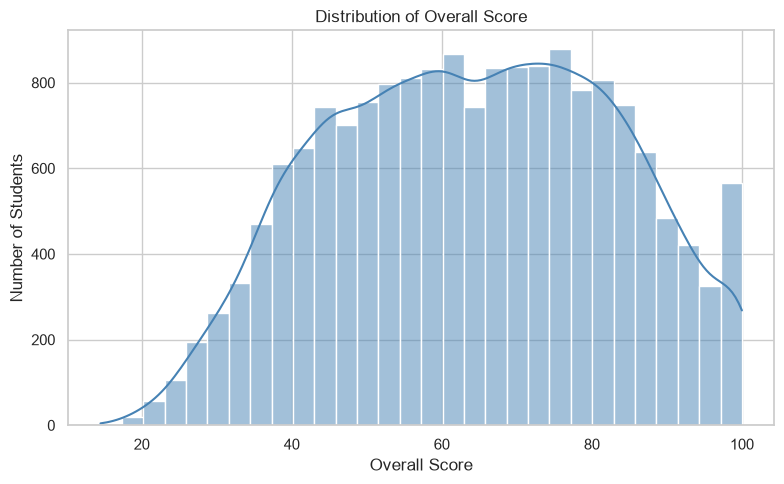

C:\Users\Master\AppData\Local\Temp\ipykernel_12316\1431429294.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=avg_by_travel.index, y=avg_by_travel.values, palette="viridis")


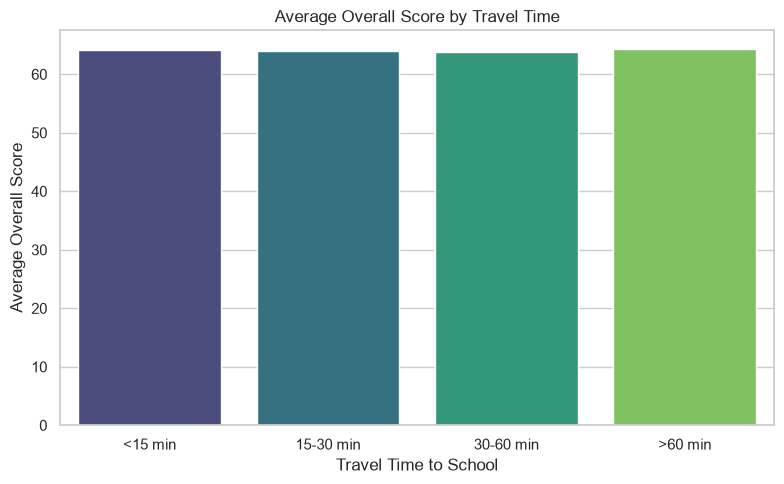

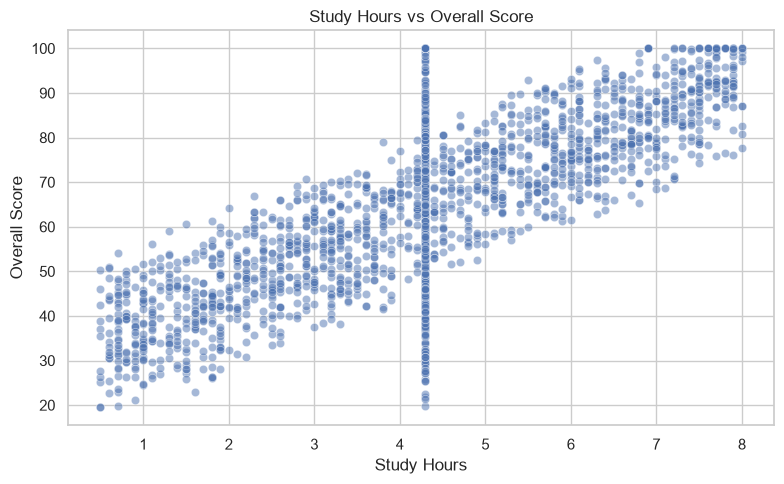

C:\Users\Master\AppData\Local\Temp\ipykernel_12316\1431429294.py:51: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=plot_df, x="grade_letter", y="overall_score",


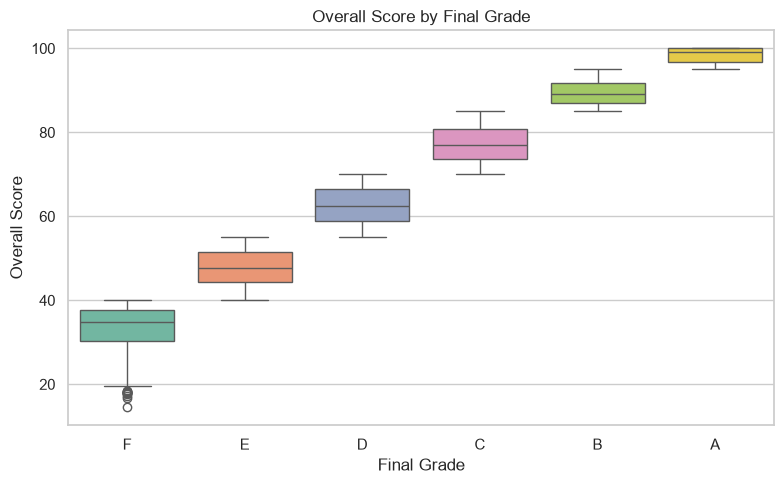

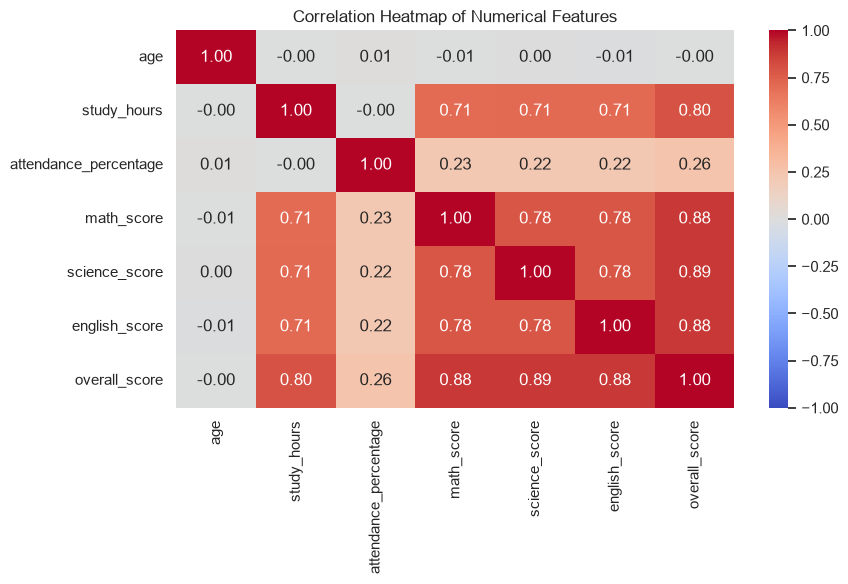

In [24]:
#Create five “different visualizations” using Matplotlib, Seaborn, or another Python visualization library:

#Each visualization must include an appropriate title and axis labels where applicable.

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")


plt.figure(figsize=(8, 5))
sns.histplot(df["overall_score"], bins=30, kde=True, color="steelblue")
plt.title("Distribution of Overall Score")
plt.xlabel("Overall Score")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()


travel_labels = {1: "<15 min", 2: "15-30 min", 3: "30-60 min", 4: ">60 min"}
avg_by_travel = df.groupby("travel_time")["overall_score"].mean().rename(index=travel_labels)

plt.figure(figsize=(8, 5))
sns.barplot(x=avg_by_travel.index, y=avg_by_travel.values, palette="viridis")
plt.title("Average Overall Score by Travel Time")
plt.xlabel("Travel Time to School")
plt.ylabel("Average Overall Score")
plt.tight_layout()
plt.show()




plt.figure(figsize=(8, 5))
sns.scatterplot(data=df.sample(2000, random_state=42),
                x="study_hours", y="overall_score", alpha=0.5)
plt.title("Study Hours vs Overall Score")
plt.xlabel("Study Hours")
plt.ylabel("Overall Score")
plt.tight_layout()
plt.show()





grade_labels = {0: "F", 1: "E", 2: "D", 3: "C", 4: "B", 5: "A"}
plot_df = df.assign(grade_letter=df["final_grade"].map(grade_labels))

plt.figure(figsize=(8, 5))
sns.boxplot(data=plot_df, x="grade_letter", y="overall_score",
            order=["F", "E", "D", "C", "B", "A"], palette="Set2")
plt.title("Overall Score by Final Grade")
plt.xlabel("Final Grade")
plt.ylabel("Overall Score")
plt.tight_layout()
plt.show()




cols = ["age", "study_hours", "attendance_percentage",
        "math_score", "science_score", "english_score", "overall_score"]

plt.figure(figsize=(9, 6))
sns.heatmap(df[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()